<a href="https://colab.research.google.com/github/anuhya-kommineni1/AgenticAI/blob/main/Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import os
import json

# Create a data directory if it doesn't exist
os.makedirs('../../data', exist_ok=True)

# Sample tickets to let the demo run
sample_tickets = [
    {
        "ticket_id": "TICK-001",
        "title": "Database is running very slowly",
        "description": "Queries against the user table are taking over 10 seconds to execute, causing timeouts in the frontend.",
        "category": "Database",
        "priority": "High"
    },
    {
        "ticket_id": "TICK-002",
        "title": "Connection pool exhausted",
        "description": "Database connections are maxing out during peak traffic hours, leading to dropped requests and high latency.",
        "category": "Database",
        "priority": "Critical"
    },
    {
        "ticket_id": "TICK-003",
        "title": "Forgot password reset link not arriving",
        "description": "Users are reporting that they click 'forgot password' but never receive the email with the reset link.",
        "category": "Authentication",
        "priority": "Medium"
    },
    {
        "ticket_id": "TICK-004",
        "title": "Payment gateway failing for international cards",
        "description": "Transactions from European customers are being declined with error code 503 by the payment processor.",
        "category": "Billing",
        "priority": "High"
    },
    {
        "ticket_id": "TICK-005",
        "title": "iOS app crashes on startup",
        "description": "App terminates unexpectedly immediately after the splash screen on iPhone devices running iOS 17.",
        "category": "Mobile",
        "priority": "High"
    },
    {
        "ticket_id": "TICK-006",
        "title": "SMTP server connection timeout",
        "description": "Transactional notification emails are failing to send because the mail server is not responding.",
        "category": "Notifications",
        "priority": "Medium"
    }
]

with open('../../data/synthetic_tickets.json', 'w') as f:
    json.dump(sample_tickets, f, indent=2)

print("Created sample synthetic_tickets.json successfully!")

Created sample synthetic_tickets.json successfully!


Initializing OpenAI client...
Using OpenAI model: text-embedding-3-small
Embedding dimension: 1536

Loading support tickets...
Loaded 6 support tickets

SAMPLE TICKET:
ID: TICK-001
Title: Database is running very slowly
Description: Queries against the user table are taking over 10 seconds to execute, causing timeouts in the frontend....
Category: Database
Priority: High

PART 1: Generating Embeddings

Generating embeddings for all tickets...
✓ Generated embeddings with shape: (6, 1536)
  (6 tickets × 1536 dimensions)

First 10 values of embedding for ticket 1:
[-0.0703125   0.06268311  0.09375    -0.01126862  0.00356293  0.04296875
  0.01997375  0.02215576  0.01197815 -0.02186584]
  (These 1536 numbers encode the semantic meaning of the text)

PART 2: Computing Similarity Scores

Search Query: 'Database is running very slowly'
Query embedding shape: (1, 1536)

Computed similarity scores for 6 tickets
Similarity range: [0.0867, 0.7061]

PART 3: Finding Most Similar Tickets

Top 5 most 

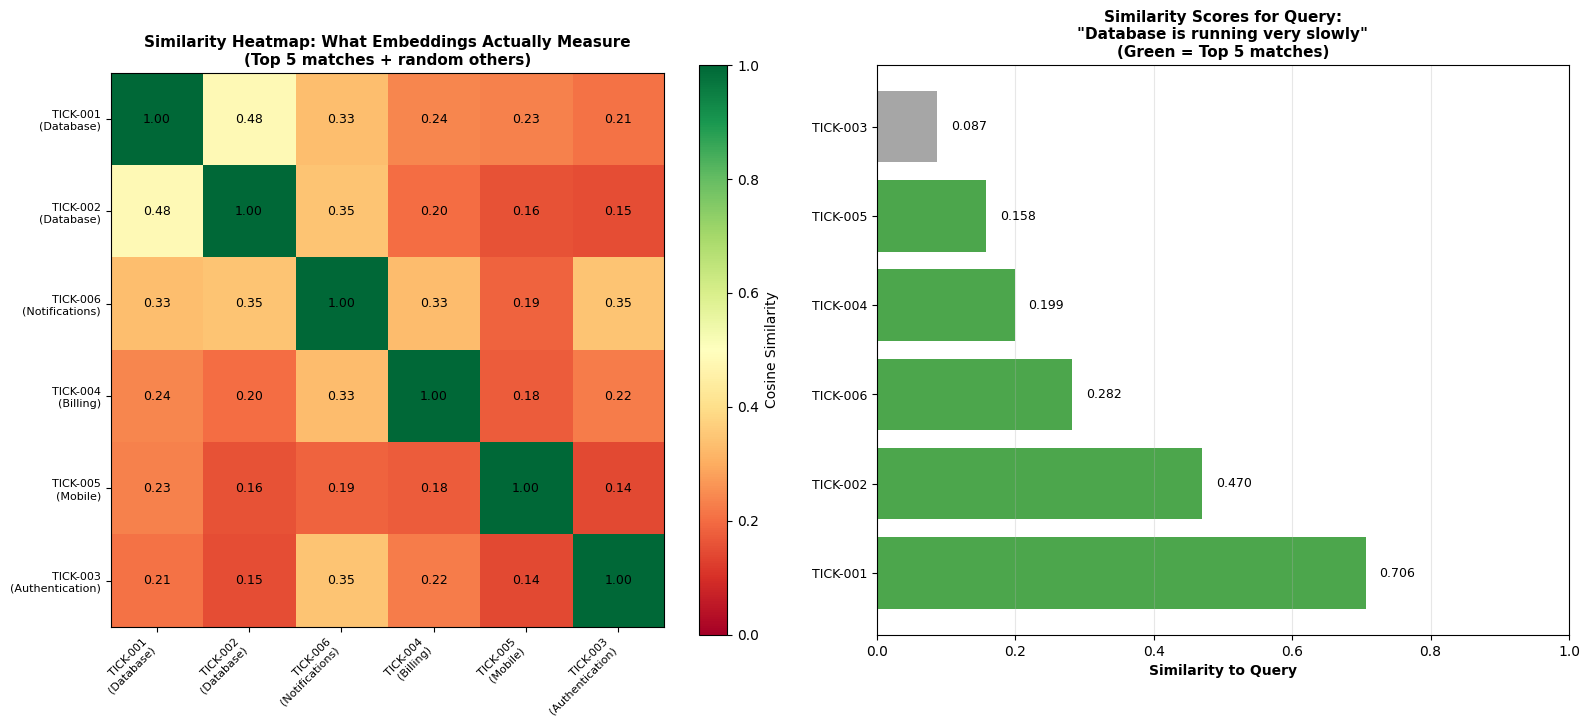


PART 5: Try Different Queries

Testing semantic search with different queries:

Query: 'Database is timing out'
  → Best match: Database is running very slowly
  → Similarity: 0.6249

Query: 'Payment not working for foreign customers'
  → Best match: Payment gateway failing for international cards
  → Similarity: 0.6193

Query: 'App crashes on iPhone'
  → Best match: iOS app crashes on startup
  → Similarity: 0.6590

Query: 'Emails are not being sent'
  → Best match: SMTP server connection timeout
  → Similarity: 0.5373

DEMO COMPLETE!

KEY TAKEAWAYS:
━━━━━━━━━━━━━━
1. EMBEDDINGS convert text → 1536-dimensional vectors
   Each vector encodes the semantic "meaning" of the text

2. COSINE SIMILARITY measures how similar two vectors are
   Range: -1 to 1 (higher = more similar)

3. SEMANTIC SEARCH finds meaning, not just keywords
   "password reset" matches "forgot credentials"!

4. THE SAME MODEL must be used for queries and documents
   Different models = incompatible vector spaces

5.

In [5]:
# -*- coding: utf-8 -*-
"""
================================================================================
MODULE 1: Embeddings & Similarity Search Demo
================================================================================

WHY EMBEDDINGS MATTER:
━━━━━━━━━━━━━━━━━━━━━
Traditional search: "password reset" only finds docs with those exact words
Semantic search:    "password reset" also finds "forgot credentials",
                    "can't log in after changing password", "auth issues"

This is the FOUNDATION of RAG - without good embeddings, retrieval fails!

WHAT YOU'LL LEARN:
━━━━━━━━━━━━━━━━━
1. How to generate embeddings from text using OpenAI
2. What embeddings actually look like (1536 numbers!)
3. Computing similarity scores (cosine similarity)
4. Finding most similar documents (semantic search)
5. Visualizing the relationships embeddings capture

THE BIG PICTURE:
━━━━━━━━━━━━━━━
    Text → [Embedding Model] → Vector (1536 floats) → [Compare] → Similarity Score

    "login fails"     →  [0.023, -0.041, ...]  ─┐
                                                 ├─→ 0.89 (similar!)
    "auth not working" → [0.019, -0.038, ...]  ─┘

LEARNING RESOURCES:
- OpenAI Embeddings Guide: https://platform.openai.com/docs/guides/embeddings
- Understanding Vector Embeddings: https://www.pinecone.io/learn/vector-embeddings/
- Cosine Similarity Explained: https://en.wikipedia.org/wiki/Cosine_similarity
"""

# =============================================================================
# IMPORTS
# =============================================================================
import json
import numpy as np              # For numerical operations on embedding vectors
import os
from openai import OpenAI       # OpenAI API client for generating embeddings
from sklearn.metrics.pairwise import cosine_similarity  # Measure similarity between vectors
import matplotlib.pyplot as plt # For visualizing embeddings
from dotenv import load_dotenv  # Load environment variables from .env file
import os
from google.colab import userdata  # Only if using Google Colab

# Option A: If using Colab Secrets (the key icon on the left)
os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

# =============================================================================
# SETUP: Load Environment Variables
# =============================================================================
# Best practice: NEVER hardcode API keys in your code!
# Store them in a .env file and load with python-dotenv
#
# Your .env file should contain:
#   OPENAI_API_KEY=sk-...
#   OPENAI_EMBEDDING_MODEL=text-embedding-3-small
# =============================================================================
#load_dotenv()

# =============================================================================
# INITIALIZE OPENAI CLIENT
# =============================================================================
print("Initializing OpenAI client...")
client = OpenAI(api_key=os.getenv('OPENAI_API_KEY'))

# =============================================================================
# EMBEDDING MODEL SELECTION
# =============================================================================
#
# OpenAI offers several embedding models (as of 2024):
#
# | Model                    | Dimensions | Cost          | Use Case            |
# |--------------------------|------------|---------------|---------------------|
# | text-embedding-3-small   | 1536       | $0.02/1M tok  | General purpose ✓   |
# | text-embedding-3-large   | 3072       | $0.13/1M tok  | Higher quality      |
# | text-embedding-ada-002   | 1536       | $0.10/1M tok  | Legacy (deprecated) |
#
# WE USE: text-embedding-3-small
#   - Good balance of quality and cost
#   - 1536 dimensions is plenty for most use cases
#   - ~6x cheaper than large model
#
# Reference: https://platform.openai.com/docs/guides/embeddings/embedding-models
# =============================================================================
embedding_model = os.getenv('OPENAI_EMBEDDING_MODEL', 'text-embedding-3-small')
embedding_dim = 1536  # Number of dimensions in the embedding vector
print(f"Using OpenAI model: {embedding_model}")
print(f"Embedding dimension: {embedding_dim}")

# =============================================================================
# LOAD DATA: Support Tickets
# =============================================================================
print("\nLoading support tickets...")
with open('../../data/synthetic_tickets.json', 'r') as f:
    tickets = json.load(f)
print(f"Loaded {len(tickets)} support tickets")

# Display sample ticket - understand what we're working with
print("\n" + "="*80)
print("SAMPLE TICKET:")
print("="*80)
sample = tickets[0]
print(f"ID: {sample['ticket_id']}")
print(f"Title: {sample['title']}")
print(f"Description: {sample['description'][:200]}...")
print(f"Category: {sample['category']}")
print(f"Priority: {sample['priority']}")

# ============================================================================
# PART 1: Generate Embeddings
# ============================================================================
#
# WHAT IS AN EMBEDDING?
# ━━━━━━━━━━━━━━━━━━━━
# A list of 1536 numbers that represents the "meaning" of text.
# Think of it as coordinates in a 1536-dimensional space where
# similar meanings are located close together.
#
# ANALOGY: If we could plot words in 2D...
#
#     "cat" ●         ● "dog"      (close = similar)
#
#                     ● "python"   (far = different meaning)
#
#     ● "car"         ● "truck"    (close = similar)
#
# But we need 1536 dimensions to capture all the nuances of language!
#
# ============================================================================
print("\n" + "="*80)
print("PART 1: Generating Embeddings")
print("="*80)

# -----------------------------------------------------------------------------
# Prepare text for embedding
# -----------------------------------------------------------------------------
# TIP: Combine relevant fields for richer context
# The more context, the better the embedding captures the meaning
#
# BAD:  Just title → "Login issue"
# GOOD: Title + description → "Login issue. User reports authentication
#       failure after password reset. Error code 401..."
# -----------------------------------------------------------------------------
ticket_texts = [
    f"{ticket['title']}. {ticket['description']}"
    for ticket in tickets
]

# -----------------------------------------------------------------------------
# Generate embeddings via OpenAI API
# -----------------------------------------------------------------------------
# This is a BATCH call - we send all texts at once for efficiency
# The API returns one embedding per input text
#
# ⚠️ RATE LIMITS: Be aware of OpenAI's rate limits for production!
# ⚠️ COST: ~$0.02 per 1M tokens for text-embedding-3-small
# -----------------------------------------------------------------------------
print("\nGenerating embeddings for all tickets...")
response = client.embeddings.create(input=ticket_texts, model=embedding_model)

# Convert API response to NumPy array for mathematical operations
# Shape: (num_tickets, 1536) - each row is one ticket's embedding
embeddings = np.array([data.embedding for data in response.data])
print(f"✓ Generated embeddings with shape: {embeddings.shape}")
print(f"  ({len(tickets)} tickets × {embedding_dim} dimensions)")

# -----------------------------------------------------------------------------
# Inspect an embedding
# -----------------------------------------------------------------------------
# You can't interpret individual values, but together they encode meaning
# Similar texts will have embeddings that point in similar directions
# -----------------------------------------------------------------------------
print(f"\nFirst 10 values of embedding for ticket 1:")
print(embeddings[0][:10])
print("  (These 1536 numbers encode the semantic meaning of the text)")

# ============================================================================
# PART 2: Compute Similarity Scores
# ============================================================================
#
# HOW DO WE COMPARE EMBEDDINGS?
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# We need a way to measure "how similar" two vectors are.
# The most common method is COSINE SIMILARITY.
#
# COSINE SIMILARITY EXPLAINED:
# ────────────────────────────
# Measures the angle between two vectors (not the distance!)
#
#     Range: -1 to 1
#     1     = identical direction (very similar)
#     0     = perpendicular (unrelated)
#     -1    = opposite direction (contradictory)
#
# WHY COSINE? (vs Euclidean distance)
# ────────────────────────────────────
# • Invariant to vector magnitude - only cares about direction
# • Works well in high dimensions (Euclidean distance suffers from "curse of dimensionality")
# • Standard in NLP and embedding-based search
#
# FORMULA: cos(θ) = (A · B) / (||A|| × ||B||)
#          (dot product divided by product of magnitudes)
#
# ============================================================================
print("\n" + "="*80)
print("PART 2: Computing Similarity Scores")
print("="*80)

# Create a search query - this is what a user might type
query = "Database is running very slowly"
print(f"\nSearch Query: '{query}'")

# -----------------------------------------------------------------------------
# Generate embedding for the query
# -----------------------------------------------------------------------------
# CRITICAL: Use the SAME model as documents!
# Different models produce incompatible vector spaces
#
# text-embedding-3-small documents + text-embedding-3-large query = WRONG!
# -----------------------------------------------------------------------------
query_response = client.embeddings.create(input=[query], model=embedding_model)
query_embedding = np.array([query_response.data[0].embedding])
print(f"Query embedding shape: {query_embedding.shape}")  # (1, 1536)

# -----------------------------------------------------------------------------
# Compute cosine similarity between query and ALL tickets
# -----------------------------------------------------------------------------
# This is the core of semantic search!
# We compare the query vector against every document vector
# Result: one similarity score per document
#
# EXACTLY what this line does:
#   similarities = cosine_similarity(query_embedding, embeddings)[0]
#
# Shapes in this demo:
#   query_embedding: (1, 1536)      -> 1 query vector
#   embeddings:      (N, 1536)      -> N ticket vectors
#   cosine_similarity(...) returns: (1, N)
#
# Why [0]?
#   There is only one query row, so [0] extracts that row,
#   giving a 1D array of length N (one score per ticket).
#
# Mini-example:
#   query_embedding = [[1, 1]]
#   embeddings      = [[1, 1], [1, 0], [-1, -1]]
#   cosine_similarity(...) -> [[1.0000, 0.7071, -1.0000]]   # shape (1, 3)
#   ...[0]                ->  [1.0000, 0.7071, -1.0000]     # shape (3,)
# -----------------------------------------------------------------------------
similarities = cosine_similarity(query_embedding, embeddings)[0]
print(f"\nComputed similarity scores for {len(similarities)} tickets")
print(f"Similarity range: [{similarities.min():.4f}, {similarities.max():.4f}]")

# ============================================================================
# PART 3: Retrieve Most Similar Tickets
# ============================================================================
#
# THIS IS SEMANTIC SEARCH!
# ━━━━━━━━━━━━━━━━━━━━━━━━
# Instead of matching keywords, we find documents with similar MEANING.
#
# The process:
# 1. Embed the query → vector
# 2. Compare to all document vectors → similarity scores
# 3. Sort by similarity → ranked results
# 4. Return top-K → most relevant documents
#
# Notice: "password reset" in query will match "forgot credentials"
#         even though they share no words!
#
# ============================================================================
print("\n" + "="*80)
print("PART 3: Finding Most Similar Tickets")
print("="*80)

# Get top-5 most similar tickets
top_k = 5

# np.argsort() returns indices that would sort the array (ascending)
# [::-1] reverses to get descending order (highest similarity first)
# [:top_k] takes only the top K results
top_indices = np.argsort(similarities)[::-1][:top_k]

print(f"\nTop {top_k} most similar tickets to query: '{query}'")
print("-" * 80)

for rank, idx in enumerate(top_indices, 1):
    ticket = tickets[idx]
    score = similarities[idx]

    print(f"\n#{rank} - Similarity: {score:.4f}")
    print(f"Ticket ID: {ticket['ticket_id']}")
    print(f"Title: {ticket['title']}")
    print(f"Category: {ticket['category']} | Priority: {ticket['priority']}")
    print(f"Description: {ticket['description'][:150]}...")

# ============================================================================
# PART 4: Visualize Embedding Relationships
# ============================================================================
#
# THE CHALLENGE WITH 1536 DIMENSIONS:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# We can't visualize 1536D space directly (humans can only see 2D/3D)
#
# OPTIONS FOR VISUALIZATION:
# ──────────────────────────
# 1. Similarity heatmap - show pairwise similarities (what we do here)
# 2. t-SNE/UMAP - project to 2D (LOSES information, can be misleading!) - OUT OF SCOPE OF THIS CLASS
# 3. PCA - linear projection (also loses information) - - OUT OF SCOPE OF THIS CLASS
#
# WE CHOOSE: Similarity heatmap
# WHY? Shows TRUE relationships without distortion
#
# TEACHING POINT:
# Don't trust dimensionality reduction plots!
# They can make distant points look close or vice versa.
# Similarity scores are the GROUND TRUTH.
#
# ============================================================================
print("\n" + "="*80)
print("PART 4: Visualizing Similarity Relationships")
print("="*80)

print("\nEmbeddings capture semantic relationships through similarity scores.")
print("Let's visualize these relationships using exact similarity measurements.\n")

# Create similarity heatmap for top tickets
print("Creating similarity heatmap...")

# Select top matches and a few random others for comparison
# This lets us see: high-similarity pairs vs. unrelated pairs
selected_indices = list(top_indices[:5]) + list(np.random.choice(
    [i for i in range(len(tickets)) if i not in top_indices[:5]],
    size=min(5, len(tickets) - 5),
    replace=False
))

# Compute similarity matrix for selected tickets
# This creates a 10x10 matrix of pairwise similarities
selected_embeddings = embeddings[selected_indices]
similarity_matrix = cosine_similarity(selected_embeddings)

# -----------------------------------------------------------------------------
# Create the visualization
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# LEFT PLOT: Similarity heatmap
# Shows pairwise similarity between all selected tickets
# Green = high similarity, Red = low similarity
im = ax1.imshow(similarity_matrix, cmap='RdYlGn', vmin=0, vmax=1)
ax1.set_xticks(range(len(selected_indices)))
ax1.set_yticks(range(len(selected_indices)))

# Label with ticket IDs and categories
labels = [f"{tickets[i]['ticket_id']}\n({tickets[i]['category']})"
          for i in selected_indices]
ax1.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax1.set_yticklabels(labels, fontsize=8)

# Add similarity values to cells (so students can read exact numbers)
for i in range(len(selected_indices)):
    for j in range(len(selected_indices)):
        text = ax1.text(j, i, f'{similarity_matrix[i, j]:.2f}',
                       ha="center", va="center", color="black", fontsize=9)

ax1.set_title('Similarity Heatmap: What Embeddings Actually Measure\n' +
             '(Top 5 matches + random others)', fontweight='bold', fontsize=11)
plt.colorbar(im, ax=ax1, label='Cosine Similarity')

# RIGHT PLOT: Query similarities bar chart
# Shows how similar each ticket is to the original query
query_similarities = [similarities[i] for i in selected_indices]
colors_bar = ['green' if i < 5 else 'gray' for i in range(len(selected_indices))]

ax2.barh(range(len(selected_indices)), query_similarities, color=colors_bar, alpha=0.7)
ax2.set_yticks(range(len(selected_indices)))
ax2.set_yticklabels([f"{tickets[i]['ticket_id']}" for i in selected_indices], fontsize=9)
ax2.set_xlabel('Similarity to Query', fontweight='bold')
ax2.set_title(f'Similarity Scores for Query:\n"{query}"\n(Green = Top 5 matches)',
             fontweight='bold', fontsize=11)
ax2.set_xlim(0, 1)
ax2.grid(axis='x', alpha=0.3)

# Add score labels on bars
for i, score in enumerate(query_similarities):
    ax2.text(score + 0.02, i, f'{score:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('embeddings_similarity_analysis.png', dpi=150, bbox_inches='tight')
print("✓ Visualization saved as 'embeddings_similarity_analysis.png'")
print("\nKEY INSIGHTS FROM THIS VISUALIZATION:")
print("  • Left heatmap: Shows TRUE pairwise similarities in 1536D space")
print("  • Right chart: Query similarity scores (what drives retrieval)")
print("  • High similarity (green) = semantically similar content")
print("  • Low similarity (red) = different topics/meanings")
print("  • These scores are EXACT - they show true relationships in 1536D space!")
plt.show(block=False)

# ============================================================================
# PART 5: Experiment with Different Queries
# ============================================================================
#
# TEACHING POINT: Show that semantic search "understands" meaning
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
#
# Notice how queries match tickets even without shared keywords:
#
# Query: "Database is timing out"
# Match: "Connection pool exhausted" (same concept, different words!)
#
# Query: "App crashes on iPhone"
# Match: "iOS application terminates unexpectedly" (synonyms work!)
#
# This is the MAGIC of embeddings!
#
# ============================================================================
print("\n" + "="*80)
print("PART 5: Try Different Queries")
print("="*80)

test_queries = [
    "Database is timing out",
    "Payment not working for foreign customers",
    "App crashes on iPhone",
    "Emails are not being sent"
]

print("\nTesting semantic search with different queries:")
for test_query in test_queries:
    # Generate query embedding
    query_resp = client.embeddings.create(input=[test_query], model=embedding_model)
    query_emb = np.array([query_resp.data[0].embedding])

    # Compare to all tickets
    sims = cosine_similarity(query_emb, embeddings)[0]
    top_idx = np.argmax(sims)

    print(f"\nQuery: '{test_query}'")
    print(f"  → Best match: {tickets[top_idx]['title']}")
    print(f"  → Similarity: {sims[top_idx]:.4f}")

# ============================================================================
# SUMMARY
# ============================================================================
print("\n" + "="*80)
print("DEMO COMPLETE!")
print("="*80)
print("""
KEY TAKEAWAYS:
━━━━━━━━━━━━━━
1. EMBEDDINGS convert text → 1536-dimensional vectors
   Each vector encodes the semantic "meaning" of the text

2. COSINE SIMILARITY measures how similar two vectors are
   Range: -1 to 1 (higher = more similar)

3. SEMANTIC SEARCH finds meaning, not just keywords
   "password reset" matches "forgot credentials"!

4. THE SAME MODEL must be used for queries and documents
   Different models = incompatible vector spaces

5. SIMILARITY SCORES are the truth
   Don't trust 2D visualizations - they lose information

CONNECTION TO RAG:
━━━━━━━━━━━━━━━━━
In RAG, we use embeddings to find relevant documents,
then pass those documents to an LLM for generation.

Query → [Embed] → [Search] → Top Documents → [LLM] → Answer

NEXT: Module 2 - Chunking & Vector Stores
""")

In [52]:
import json
import os
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter
)
from langchain_community.vectorstores import Chroma
from langchain_openai import OpenAIEmbeddings
from langchain_core.documents import Document
from dotenv import load_dotenv

load_dotenv()

# Initialize embeddings
embeddings = OpenAIEmbeddings(model='text-embedding-3-small')

# Load data
print("Loading data...")
with open('../../data/synthetic_tickets.json', 'r') as f:
    tickets = json.load(f)

# Create documents
documents = []
for ticket in tickets:
    full_text = f"""
Ticket ID: {ticket['ticket_id']}
Title: {ticket['title']}
Category: {ticket['category']}
Priority: {ticket['priority']}
Description: {ticket['description']}
Resolution: {ticket.get('resolution','N/A')}
    """.strip()

    doc = Document(
        page_content=full_text,
        metadata={
            'ticket_id': ticket.get('ticket_id', 'N/A'),
            'category': ticket.get('category', 'N/A'),
            'priority': ticket.get('priority', 'N/A')
        }
    )
    documents.append(doc)

print(f"✓ Loaded {len(documents)} documents\n")


# ============================================================================
# Exercise 1: Change the Chunk Size (Easy)
# ============================================================================
print("=" * 80)
print("EXERCISE 1: Change the Chunk Size")
print("=" * 80)

# Original: chunk_size=200, chunk_overlap=20
# Solution: chunk_size=500, chunk_overlap=50

original_splitter = CharacterTextSplitter(chunk_size=200, chunk_overlap=20, separator="\n")
original_chunks = original_splitter.split_documents(documents)

new_splitter = CharacterTextSplitter(chunk_size=500, chunk_overlap=50, separator="\n")
new_chunks = new_splitter.split_documents(documents)

print(f"\nOriginal (200 chars): {len(original_chunks)} chunks")
print(f"New (500 chars): {len(new_chunks)} chunks")
print(f"\n→ Larger chunk size = fewer chunks")


# ============================================================================
# Exercise 2: Change the Search Query (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 2: Change the Search Query")
print("=" * 80)

# Build a simple store for testing
store = Chroma.from_documents(documents, embeddings, collection_name="exercise2")

queries = [
    "Database is timing out frequently",
    "Email notifications not working",
    "Payment processing fails"
]

for query in queries:
    results = store.similarity_search(query, k=1)
    if results:
        print(f"\nQuery: '{query}'")
        print(f"  Best match: {results[0].metadata['ticket_id']}")
        print(f"  Category: {results[0].metadata['category']}")


# ============================================================================
# Exercise 3: Adjust Number of Results (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 3: Adjust Number of Results")
print("=" * 80)

query = "Authentication problems"

# k=3 (original)
results_3 = store.similarity_search(query, k=3)
print("\nTop 3 results:")
for i, doc in enumerate(results_3, 1):
    print(f"  {i}. {doc.metadata['ticket_id']}")

# k=5 (changed)
results_5 = store.similarity_search(query, k=5)
print("\nTop 5 results:")
for i, doc in enumerate(results_5, 1):
    print(f"  {i}. {doc.metadata['ticket_id']}")


# ============================================================================
# Exercise 4: Try Different Metadata Filters (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 4: Try Different Metadata Filters")
print("=" * 80)

# Chroma supports filtering
chroma_store = Chroma.from_documents(
    documents,
    embeddings,
    collection_name="filter_test"
)

categories = ["Authentication", "Database", "Performance", "Email"]
query = "system not working"

for category in categories:
    try:
        results = chroma_store.similarity_search(
            query, k=2, filter={"category": category}
        )
        print(f"\nCategory: {category}")
        for doc in results:
            print(f"  {doc.metadata['ticket_id']}: {doc.page_content[:50]}...")
    except Exception as e:
        print(f"\nCategory: {category} - No matches or error")


# ============================================================================
# Exercise 5: Compare Chunk Sizes (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 5: Compare Chunk Sizes")
print("=" * 80)

chunk_sizes = [100, 200, 300, 500, 1000]

print(f"\nTotal documents: {len(documents)}")
print(f"Avg document length: {sum(len(d.page_content) for d in documents) // len(documents)} chars")
print()
print("Chunk Size | # Chunks | Avg Chunk Length")
print("-" * 45)

for size in chunk_sizes:
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=size,
        chunk_overlap=size // 10
    )
    chunks = splitter.split_documents(documents)
    avg_len = sum(len(c.page_content) for c in chunks) // len(chunks) if chunks else 0
    print(f"{size:>10} | {len(chunks):>8} | {avg_len:>16}")


# ============================================================================
# Exercise 6: Add Similarity Scores to Results (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 6: Add Similarity Scores to Results")
print("=" * 80)

query = "login authentication error"
results_with_scores = store.similarity_search_with_score(query, k=5)

print(f"\nQuery: '{query}'")
print("\nResults with distance scores:")
print("-" * 50)
for i, (doc, score) in enumerate(results_with_scores, 1):
    print(f"#{i} - Distance: {score:.4f}")
    print(f"   Ticket: {doc.metadata['ticket_id']}")
    print(f"   Category: {doc.metadata['category']}")

print("\n→ Lower score = more similar (Chroma uses L2 distance)")


# ============================================================================
# Exercise 7: Filter by Multiple Conditions (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 7: Filter by Multiple Conditions")
print("=" * 80)

query = "system not working"

# Combined filter: category AND priority
combined_filter = {"$and": [{"category": "Authentication"}, {"priority": "High"}]}

try:
    results = chroma_store.similarity_search(query, k=3, filter=combined_filter)

    print(f"\nQuery: '{query}'")
    print(f"Filter: Authentication category + High priority")
    print(f"\nResults ({len(results)}):")
    for doc in results:
        print(f"  [{doc.metadata['priority']}] [{doc.metadata['category']}] {doc.metadata['ticket_id']}")
except Exception as e:
    print(f"No results matching filter or error: {e}")


# ============================================================================
# Exercise 8: Save and Load Vector Store (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 8: Save and Load Vector Store")
print("=" * 80)

# Build documents for Chroma
simple_docs = [
    Document(
        page_content=f"{t['title']}. {t['description']}",
        metadata={'ticket_id': t.get('ticket_id', 'N/A'), 'category':t.get('category', 'N/A')}
    )
    for t in tickets
]

# Step 1: Build and save (Chroma persists automatically with persist_directory)
print("\nBuilding vector store...")
persist_dir = "./solution_chroma_db"
chroma_store = Chroma.from_documents(
    simple_docs,
    embeddings,
    collection_name="exercise8",
    persist_directory=persist_dir
)
print(f"✓ Saved to {persist_dir}")

# Step 2: Load it back (create new Chroma instance pointing to same directory)
print("\nLoading vector store...")
loaded_store = Chroma(
    persist_directory=persist_dir,
    embedding_function=embeddings,
    collection_name="exercise8"
)
print("✓ Loaded from disk")

# Step 3: Verify it works
query = "login problem"
results = loaded_store.similarity_search(query, k=3)
print(f"\nSearch results for '{query}':")
for doc in results:
    print(f"  {doc.metadata['ticket_id']}: {doc.page_content[:50]}...")


# ============================================================================
# Cleanup
# ============================================================================
print("\n" + "=" * 80)
print("CLEANUP")
print("=" * 80)

import shutil
if os.path.exists("./solution_chroma_db"):
    shutil.rmtree("./solution_chroma_db")
    print("✓ Cleaned up solution_chroma_db")


# ============================================================================
# Summary
# ============================================================================
print("\n" + "=" * 80)
print("ALL SOLUTIONS COMPLETE!")
print("=" * 80)
print("""
Key Takeaways:
──────────────
1. Larger chunk size = fewer chunks, but may lose precision
2. Different queries find different relevant documents
3. Metadata filtering narrows search to specific categories/priorities
4. Chroma returns distance scores (lower = more similar)
5. Persisting vector stores saves embedding computation time

Next: Move on to Module 3 - Indexing Strategies!
""")

Loading data...
✓ Loaded 6 documents

EXERCISE 1: Change the Chunk Size

Original (200 chars): 12 chunks
New (500 chars): 6 chunks

→ Larger chunk size = fewer chunks

EXERCISE 2: Change the Search Query

Query: 'Database is timing out frequently'
  Best match: TICK-001
  Category: Database

Query: 'Email notifications not working'
  Best match: TICK-006
  Category: Notifications

Query: 'Payment processing fails'
  Best match: TICK-004
  Category: Billing

EXERCISE 3: Adjust Number of Results

Top 3 results:
  1. TICK-003
  2. TICK-004
  3. TICK-001

Top 5 results:
  1. TICK-003
  2. TICK-004
  3. TICK-001
  4. TICK-006
  5. TICK-002

EXERCISE 4: Try Different Metadata Filters

Category: Authentication
  TICK-003: Ticket ID: TICK-003
Title: Forgot password reset l...

Category: Database
  TICK-001: Ticket ID: TICK-001
Title: Database is running ver...
  TICK-002: Ticket ID: TICK-002
Title: Connection pool exhaust...

Category: Performance

Category: Email

EXERCISE 5: Compare Chunk Si

In [53]:
# Module 3 : Indexing Strategies

import json
import time
import os
import shutil
from dotenv import load_dotenv
from llama_index.core import (
    VectorStoreIndex, SummaryIndex, TreeIndex, KeywordTableIndex,
    Document, Settings, StorageContext, load_index_from_storage
)
from llama_index.core.vector_stores import MetadataFilters, ExactMatchFilter
from llama_index.embeddings.openai import OpenAIEmbedding
from llama_index.llms.openai import OpenAI

load_dotenv()

# Configure LlamaIndex
Settings.embed_model = OpenAIEmbedding(model='text-embedding-3-small')
Settings.llm = OpenAI(model='gpt-4o-mini')

# Load data
print("Loading data...")
with open('../../data/synthetic_tickets.json', 'r', encoding='utf-8') as f:
    tickets = json.load(f)

documents = [
    Document(
        text=f"Title: {t.get('title', 'N/A')}\nDescription: {t.get('description', 'N/A')}\nResolution: {t.get('resolution', 'N/A')}",
        metadata={
            'ticket_id': t.get('ticket_id', 'N/A'),
            'category': t.get('category', 'N/A'),
            'priority': t.get('priority', 'N/A')
        }
    )
    for t in tickets
]
print(f"✓ Loaded {len(documents)} documents\n")

# Build vector index (fast - just embeddings, no LLM calls)
print("Building Vector Index...")
vector_index = VectorStoreIndex.from_documents(documents)
print("✓ Vector Index built\n")


# ============================================================================
# Exercise 1: Change the Query (Easy)
# ============================================================================
print("=" * 80)
print("EXERCISE 1: Change the Query")
print("=" * 80)

# Build a simple vector index for testing
vector_index = VectorStoreIndex.from_documents(documents)
query_engine = vector_index.as_query_engine(similarity_top_k=3)

queries = [
    "How do I fix authentication issues after password reset?",  # Original
    "Database connection is timing out",  # Changed
    "Email notifications not being delivered"
]

for query in queries:
    response = query_engine.query(query)
    print(f"\nQuery: '{query}'")
    print(f"Answer: {str(response)[:150]}...")


# ============================================================================
# Exercise 2: Adjust the Number of Results (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 2: Adjust the Number of Results")
print("=" * 80)

query = "authentication login problem"

# top_k = 3 (original)
engine_3 = vector_index.as_query_engine(similarity_top_k=3)
response_3 = engine_3.query(query)
print(f"\nWith similarity_top_k=3:")
print(f"  Sources: {len(response_3.source_nodes)} documents used")

# top_k = 5 (changed)
engine_5 = vector_index.as_query_engine(similarity_top_k=5)
response_5 = engine_5.query(query)
print(f"\nWith similarity_top_k=5:")
print(f"  Sources: {len(response_5.source_nodes)} documents used")


# ============================================================================
# Exercise 3: Change the Tree Index Branch Factor (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 3: Change the Tree Index Branch Factor")
print("=" * 80)

# NOTE: Tree Index is SLOW to build (makes many LLM calls to generate summaries)
# Skipping in solutions to avoid API timeouts
# In the demo, the Tree Index is already built, so modifying branch_factor is fast

print("\n→ SKIPPED: Tree Index takes too long to build (many LLM calls)")
print("→ To test: Modify the branch_factor in demo.py and run the demo instead")
print("→ tree_query_engine = tree_index.as_query_engine(child_branch_factor=1)")
print("→ tree_query_engine = tree_index.as_query_engine(child_branch_factor=3)")


# ============================================================================
# Exercise 4: Test a Keyword-Specific Query (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 4: Test a Keyword-Specific Query")
print("=" * 80)

print("\nBuilding Keyword Index (this may take 1-2 minutes)...")
keyword_index = KeywordTableIndex.from_documents(documents)
keyword_engine = keyword_index.as_query_engine()
print("✓ Keyword Index built")

keyword_queries = ["TICK-001", "authentication", "database timeout"]

for query in keyword_queries:
    response = keyword_engine.query(query)
    print(f"\nKeyword query: '{query}'")
    print(f"  Answer: {str(response)[:150]}...")


# ============================================================================
# Exercise 5: Compare Index Types Side-by-Side (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 5: Compare Index Types Side-by-Side")
print("=" * 80)

test_queries = [
    "authentication login problem",  # Semantic query
    "database timeout error",        # Semantic query
    "TICK-005"                       # Exact match query
]

for query in test_queries:
    print(f"\n{'='*60}")
    print(f"Query: '{query}'")
    print("=" * 60)

    # Vector Index
    vec_response = vector_index.as_query_engine(similarity_top_k=3).query(query)
    print(f"\nVector Index:")
    print(f"  {str(vec_response)[:150]}...")

    # Keyword Index
    kw_response = keyword_index.as_query_engine().query(query)
    print(f"\nKeyword Index:")
    print(f"  {str(kw_response)[:150]}...")


# ============================================================================
# Exercise 6: Save and Load an Index (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 6: Save and Load an Index")
print("=" * 80)

# Step 1: Save to disk
persist_dir = "./solution_saved_index"
print(f"\nSaving index to {persist_dir}...")
vector_index.storage_context.persist(persist_dir=persist_dir)
print("✓ Saved")

# Step 2: Load from disk
print("\nLoading index from disk...")
storage_context = StorageContext.from_defaults(persist_dir=persist_dir)
loaded_index = load_index_from_storage(storage_context)
print("✓ Loaded")

# Step 3: Test it works
query = "login problem"
response = loaded_index.as_query_engine().query(query)
print(f"\nQuery: '{query}'")
print(f"Result: {str(response)[:150]}...")

# Cleanup
shutil.rmtree(persist_dir)
print(f"\n✓ Cleaned up {persist_dir}")


# ============================================================================
# Exercise 7: Add Metadata Filtering (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 7: Add Metadata Filtering")
print("=" * 80)

query = "system problem"

# Without filter
print("\nWithout filter:")
response = vector_index.as_query_engine(similarity_top_k=3).query(query)
print(f"  {str(response)[:150]}...")

# With category filter
categories = ["Authentication", "Database", "Performance"]

for category in categories:
    filters = MetadataFilters(filters=[
        ExactMatchFilter(key="category", value=category)
    ])
    filtered_engine = vector_index.as_query_engine(similarity_top_k=3, filters=filters)

    try:
        filtered_response = filtered_engine.query(query)
        print(f"\nWith '{category}' filter:")
        print(f"  {str(filtered_response)[:100]}...")
    except Exception as e:
        print(f"\nWith '{category}' filter: No matching documents")


# ============================================================================
# Exercise 8: Benchmark Index Build Time (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 8: Benchmark Index Build Time")
print("=" * 80)

print(f"\nBuilding indexes for {len(documents)} documents...\n")

# Vector Index
start = time.time()
_ = VectorStoreIndex.from_documents(documents)
vector_time = time.time() - start
print(f"Vector Index: {vector_time:.2f}s")

# Keyword Index
start = time.time()
_ = KeywordTableIndex.from_documents(documents)
keyword_time = time.time() - start
print(f"Keyword Index: {keyword_time:.2f}s")

# Summary Index
start = time.time()
_ = SummaryIndex.from_documents(documents)
summary_time = time.time() - start
print(f"Summary Index: {summary_time:.2f}s")

print(f"\n→ Vector Index takes longer because it generates embeddings")
print(f"→ Keyword Index uses LLM to extract keywords")
print(f"→ Summary Index just stores documents (work at query time)")


# ============================================================================
# Bonus: Simple Hybrid Search (Challenge)
# ============================================================================
print("\n" + "=" * 80)
print("BONUS: Simple Hybrid Search")
print("=" * 80)

query = "authentication timeout error"

# Get retrievers
vector_retriever = vector_index.as_retriever(similarity_top_k=5)
keyword_retriever = keyword_index.as_retriever()

# Retrieve from both
print(f"\nQuery: '{query}'\n")

print("Vector Results:")
vector_nodes = vector_retriever.retrieve(query)
for i, node in enumerate(vector_nodes[:3], 1):
    print(f"  {i}. {node.node.metadata.get('ticket_id', 'N/A')}")

print("\nKeyword Results:")
keyword_nodes = keyword_retriever.retrieve(query)
for i, node in enumerate(keyword_nodes[:3], 1):
    print(f"  {i}. {node.node.metadata.get('ticket_id', 'N/A')}")

# Simple hybrid: combine and deduplicate
seen = set()
hybrid_results = []
for node in vector_nodes + keyword_nodes:
    ticket_id = node.node.metadata.get('ticket_id')
    if ticket_id and ticket_id not in seen:
        seen.add(ticket_id)
        hybrid_results.append(ticket_id)

print(f"\nHybrid Results (combined): {hybrid_results[:5]}")


# ============================================================================
# Summary
# ============================================================================
print("\n" + "=" * 80)
print("ALL SOLUTIONS COMPLETE!")
print("=" * 80)
print("""
Key Takeaways:
──────────────
1. Vector Index: Best for semantic/meaning-based queries
2. Keyword Index: Best for exact term matching (IDs, error codes)
3. Tree Index: Good for large hierarchical documents
4. Summary Index: Good for high-level queries on small datasets
5. Hybrid: Combine vector + keyword for best coverage
6. Always persist indexes to save rebuild time and API costs

Next: Move on to Module 4 - RAG Pipeline!
""")

Loading data...
✓ Loaded 6 documents

Building Vector Index...
✓ Vector Index built

EXERCISE 1: Change the Query

Query: 'How do I fix authentication issues after password reset?'
Answer: To address authentication issues after a password reset, ensure that the reset link is received and used within the specified time frame. If users are...

Query: 'Database connection is timing out'
Answer: The issue of database connections timing out is likely related to the connection pool being exhausted during peak traffic hours, which can lead to dro...

Query: 'Email notifications not being delivered'
Answer: There is an issue with transactional notification emails failing to send due to a timeout with the mail server connection. This could be related to th...

EXERCISE 2: Adjust the Number of Results

With similarity_top_k=3:
  Sources: 3 documents used

With similarity_top_k=5:
  Sources: 5 documents used

EXERCISE 3: Change the Tree Index Branch Factor

→ SKIPPED: Tree Index takes too long to

In [8]:
!pip install langchain-text-splitters langchain-openai langchain-community chromadb python-dotenv langchain-experimental

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.4/146.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 100.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.8/573.8 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.0/869.0 kB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.

In [17]:
import json
import time
import os
import shutil
from dotenv import load_dotenv
from llama_index.core import (
    VectorStoreIndex, SummaryIndex, TreeIndex, KeywordTableIndex,
    Document, Settings, StorageContext, load_index_from_storage
)
from llama_index.core.vector_stores import MetadataFilters, ExactMatchFilter
from llama_index.embeddings.openai import OpenAIEmbedding
from llama_index.llms.openai import OpenAI

import os
from google.colab import userdata  # Only if using Google Colab

# If using Colab Secrets (the key icon on the left)
os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

#load_dotenv()

# Configure LlamaIndex
Settings.embed_model = OpenAIEmbedding(model='text-embedding-3-small')
Settings.llm = OpenAI(model='gpt-4o-mini')

# Load data
print("Loading data...")
with open('../../data/synthetic_tickets.json', 'r', encoding='utf-8') as f:
    tickets = json.load(f)

documents = [
    Document(
        text=f"Title: {t.get('title', 'N/A')}\nDescription: {t.get('description', 'N/A')}\nResolution: {t.get('resolution', 'N/A')}",
        metadata={
            'ticket_id': t.get('ticket_id', 'N/A'),
            'category': t.get('category', 'N/A'),
            'priority': t.get('priority', 'N/A')
        }
    )
    for t in tickets
]

print(f"✓ Loaded {len(documents)} documents\n")

# Build vector index (fast - just embeddings, no LLM calls)
print("Building Vector Index...")
vector_index = VectorStoreIndex.from_documents(documents)
print("✓ Vector Index built\n")


# ============================================================================
# Exercise 1: Change the Query (Easy)
# ============================================================================
print("=" * 80)
print("EXERCISE 1: Change the Query")
print("=" * 80)

# Build a simple vector index for testing
vector_index = VectorStoreIndex.from_documents(documents)
query_engine = vector_index.as_query_engine(similarity_top_k=3)

queries = [
    "How do I fix authentication issues after password reset?",  # Original
    "Database connection is timing out",  # Changed
    "Email notifications not being delivered"
]

for query in queries:
    response = query_engine.query(query)
    print(f"\nQuery: '{query}'")
    print(f"Answer: {str(response)[:150]}...")


# ============================================================================
# Exercise 2: Adjust the Number of Results (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 2: Adjust the Number of Results")
print("=" * 80)

query = "authentication login problem"

# top_k = 3 (original)
engine_3 = vector_index.as_query_engine(similarity_top_k=3)
response_3 = engine_3.query(query)
print(f"\nWith similarity_top_k=3:")
print(f"  Sources: {len(response_3.source_nodes)} documents used")

# top_k = 5 (changed)
engine_5 = vector_index.as_query_engine(similarity_top_k=5)
response_5 = engine_5.query(query)
print(f"\nWith similarity_top_k=5:")
print(f"  Sources: {len(response_5.source_nodes)} documents used")


# ============================================================================
# Exercise 3: Change the Tree Index Branch Factor (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 3: Change the Tree Index Branch Factor")
print("=" * 80)

# NOTE: Tree Index is SLOW to build (makes many LLM calls to generate summaries)
# Skipping in solutions to avoid API timeouts
# In the demo, the Tree Index is already built, so modifying branch_factor is fast

print("\n→ SKIPPED: Tree Index takes too long to build (many LLM calls)")
print("→ To test: Modify the branch_factor in demo.py and run the demo instead")
print("→ tree_query_engine = tree_index.as_query_engine(child_branch_factor=1)")
print("→ tree_query_engine = tree_index.as_query_engine(child_branch_factor=3)")


# ============================================================================
# Exercise 4: Test a Keyword-Specific Query (Easy)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 4: Test a Keyword-Specific Query")
print("=" * 80)

print("\nBuilding Keyword Index (this may take 1-2 minutes)...")
keyword_index = KeywordTableIndex.from_documents(documents)
keyword_engine = keyword_index.as_query_engine()
print("✓ Keyword Index built")

keyword_queries = ["TICK-001", "authentication", "database timeout"]

for query in keyword_queries:
    response = keyword_engine.query(query)
    print(f"\nKeyword query: '{query}'")
    print(f"  Answer: {str(response)[:150]}...")


# ============================================================================
# Exercise 5: Compare Index Types Side-by-Side (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 5: Compare Index Types Side-by-Side")
print("=" * 80)

test_queries = [
    "authentication login problem",  # Semantic query
    "database timeout error",        # Semantic query
    "TICK-005"                       # Exact match query
]

for query in test_queries:
    print(f"\n{'='*60}")
    print(f"Query: '{query}'")
    print("=" * 60)

    # Vector Index
    vec_response = vector_index.as_query_engine(similarity_top_k=3).query(query)
    print(f"\nVector Index:")
    print(f"  {str(vec_response)[:150]}...")

    # Keyword Index
    kw_response = keyword_index.as_query_engine().query(query)
    print(f"\nKeyword Index:")
    print(f"  {str(kw_response)[:150]}...")


# ============================================================================
# Exercise 6: Save and Load an Index (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 6: Save and Load an Index")
print("=" * 80)

# Step 1: Save to disk
persist_dir = "./solution_saved_index"
print(f"\nSaving index to {persist_dir}...")
vector_index.storage_context.persist(persist_dir=persist_dir)
print("✓ Saved")

# Step 2: Load from disk
print("\nLoading index from disk...")
storage_context = StorageContext.from_defaults(persist_dir=persist_dir)
loaded_index = load_index_from_storage(storage_context)
print("✓ Loaded")

# Step 3: Test it works
query = "login problem"
response = loaded_index.as_query_engine().query(query)
print(f"\nQuery: '{query}'")
print(f"Result: {str(response)[:150]}...")

# Cleanup
shutil.rmtree(persist_dir)
print(f"\n✓ Cleaned up {persist_dir}")


# ============================================================================
# Exercise 7: Add Metadata Filtering (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 7: Add Metadata Filtering")
print("=" * 80)

query = "system problem"

# Without filter
print("\nWithout filter:")
response = vector_index.as_query_engine(similarity_top_k=3).query(query)
print(f"  {str(response)[:150]}...")

# With category filter
categories = ["Authentication", "Database", "Performance"]

for category in categories:
    filters = MetadataFilters(filters=[
        ExactMatchFilter(key="category", value=category)
    ])
    filtered_engine = vector_index.as_query_engine(similarity_top_k=3, filters=filters)

    try:
        filtered_response = filtered_engine.query(query)
        print(f"\nWith '{category}' filter:")
        print(f"  {str(filtered_response)[:100]}...")
    except Exception as e:
        print(f"\nWith '{category}' filter: No matching documents")


# ============================================================================
# Exercise 8: Benchmark Index Build Time (Medium)
# ============================================================================
print("\n" + "=" * 80)
print("EXERCISE 8: Benchmark Index Build Time")
print("=" * 80)

print(f"\nBuilding indexes for {len(documents)} documents...\n")

# Vector Index
start = time.time()
_ = VectorStoreIndex.from_documents(documents)
vector_time = time.time() - start
print(f"Vector Index: {vector_time:.2f}s")

# Keyword Index
start = time.time()
_ = KeywordTableIndex.from_documents(documents)
keyword_time = time.time() - start
print(f"Keyword Index: {keyword_time:.2f}s")

# Summary Index
start = time.time()
_ = SummaryIndex.from_documents(documents)
summary_time = time.time() - start
print(f"Summary Index: {summary_time:.2f}s")

print(f"\n→ Vector Index takes longer because it generates embeddings")
print(f"→ Keyword Index uses LLM to extract keywords")
print(f"→ Summary Index just stores documents (work at query time)")


# ============================================================================
# Bonus: Simple Hybrid Search (Challenge)
# ============================================================================
print("\n" + "=" * 80)
print("BONUS: Simple Hybrid Search")
print("=" * 80)

query = "authentication timeout error"

# Get retrievers
vector_retriever = vector_index.as_retriever(similarity_top_k=5)
keyword_retriever = keyword_index.as_retriever()

# Retrieve from both
print(f"\nQuery: '{query}'\n")

print("Vector Results:")
vector_nodes = vector_retriever.retrieve(query)
for i, node in enumerate(vector_nodes[:3], 1):
    print(f"  {i}. {node.node.metadata.get('ticket_id', 'N/A')}")

print("\nKeyword Results:")
keyword_nodes = keyword_retriever.retrieve(query)
for i, node in enumerate(keyword_nodes[:3], 1):
    print(f"  {i}. {node.node.metadata.get('ticket_id', 'N/A')}")

# Simple hybrid: combine and deduplicate
seen = set()
hybrid_results = []
for node in vector_nodes + keyword_nodes:
    ticket_id = node.node.metadata.get('ticket_id')
    if ticket_id and ticket_id not in seen:
        seen.add(ticket_id)
        hybrid_results.append(ticket_id)

print(f"\nHybrid Results (combined): {hybrid_results[:5]}")


# ============================================================================
# Summary
# ============================================================================
print("\n" + "=" * 80)
print("ALL SOLUTIONS COMPLETE!")
print("=" * 80)
print("""
Key Takeaways:
──────────────
1. Vector Index: Best for semantic/meaning-based queries
2. Keyword Index: Best for exact term matching (IDs, error codes)
3. Tree Index: Good for large hierarchical documents
4. Summary Index: Good for high-level queries on small datasets
5. Hybrid: Combine vector + keyword for best coverage
6. Always persist indexes to save rebuild time and API costs

Next: Move on to Module 4 - RAG Pipeline!
""")

Loading data...
✓ Loaded 6 documents

Building Vector Index...
✓ Vector Index built

EXERCISE 1: Change the Query

Query: 'How do I fix authentication issues after password reset?'
Answer: To address authentication issues after a password reset, ensure that the reset link is received and used correctly. If users are not receiving the res...

Query: 'Database connection is timing out'
Answer: The issue of database connections timing out is likely related to the connection pool being exhausted during peak traffic hours, which can lead to dro...

Query: 'Email notifications not being delivered'
Answer: There is an issue with transactional notification emails failing to send due to a timeout with the mail server connection. Additionally, users are exp...

EXERCISE 2: Adjust the Number of Results

With similarity_top_k=3:
  Sources: 3 documents used

With similarity_top_k=5:
  Sources: 5 documents used

EXERCISE 3: Change the Tree Index Branch Factor

→ SKIPPED: Tree Index takes too long to

In [13]:
pip install llama-index llama-index-core llama-index-embeddings-openai llama-index-llms-openai python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.3/183.3 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.4/169.4 kB 7.3 MB/s eta 0:00:00
  Attempting uninstall: nltk
    Found existing installation: nltk 3.9.1
    Uninstalling nltk-3.9.1:
      Successfully uninstalled nltk-3.9.1
